# Visualisation des résultats des modèles de ML - détection de l'hypovigilance

## Cellule 0 : Imports, Configuration & Filtre des 5 modèles

In [18]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(context="notebook", style="whitegrid")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12})

# ============================================================
# CHEMINS DES DEUX FICHIERS EXCEL
# ============================================================
EXCEL_PARTICIPANT = Path("RESULTS_finaux_zscore_per_participant") / "recap_final_zscore_participant_wpooled.xlsx"
EXCEL_CALIBRATION = Path("RESULTS_finaux_zscore_calibration") / "recap_final_zscore_calibration.xlsx"

FIG_DIR = Path("FIGURES_COMPARISON_NORMS")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SAVE_FIG = True
DPI = 200

# ============================================================
# FILTRES & ORDRES LOGIQUES
# ============================================================
PRIMARY_METRIC = "average_precision"
GUARD_ROC_CI_LOW = 0.5  # Garde-fou anti-hasard

# Restriction stricte aux 5 modèles demandés
KEEP_MODELS = [
    "RandomForest",
    "ExtraTrees",
    "HistGradientBoosting",
    "XGBoost",
    "CatBoost"
]

FOLDER_ORDER = [
    "short_step10_nirs20_bio60",
    "medium_step15_nirs30_bio120",
    "long_step30_nirs60_bio180",
]
FOLDER_LABELS = {
    "short_step10_nirs20_bio60":   "Short",
    "medium_step15_nirs30_bio120": "Medium",
    "long_step30_nirs60_bio180":   "Long",
}

FILE_ORDER = [
    "ds_nirs.csv",
    "ds_nirs_rsp.csv",
    "ds_nirs_ecg.csv",
    "ds_nirs_ecg_rsp.csv",
]
FILE_LABELS = {
    "ds_nirs.csv":         "fNIRS",
    "ds_nirs_rsp.csv":     "fNIRS+RSP",
    "ds_nirs_ecg.csv":     "fNIRS+ECG",
    "ds_nirs_ecg_rsp.csv": "fNIRS+ECG+RSP",
}

# Ordre logique et libellés propres des réductions fNIRS
REDUCTION_ORDER = [
    "full_decorr_fnirs",
    "fnirs_topk_corr_k40",
    "fnirs_topk_corr_k80",
    "fnirs_topk_corr_k120",
    "fnirs_global_chrom",
    "fnirs_global_chrom_decorr",
    "fnirs_hemi_chrom",
    "fnirs_hemi_chrom_decorr",
]

REDUCTION_LABELS = {
    "full_decorr_fnirs":          "Full Décorr.",
    "fnirs_topk_corr_k40":        "Top-40 Décorr.",
    "fnirs_topk_corr_k80":        "Top-80 Décorr.",
    "fnirs_topk_corr_k120":       "Top-120 Décorr.",
    "fnirs_global_chrom":         "Global Chrom.",
    "fnirs_global_chrom_decorr":  "Global Chrom. + Décorr.",
    "fnirs_hemi_chrom":           "Hémi. Chrom.",
    "fnirs_hemi_chrom_decorr":    "Hémi. Chrom. + Décorr.",
}

# Application du formattage dans le DataFrame summary
summary["reduction_label"] = summary["reduction_mode"].map(REDUCTION_LABELS).fillna(summary["reduction_mode"])
summary["reduction_label"] = order_categorical(
    summary["reduction_label"], 
    [REDUCTION_LABELS.get(r, r) for r in REDUCTION_ORDER]
)

BASELINE_FILE = "ds_nirs.csv"

# Palette pour les normalisations
NORM_PALETTE = {
    "Participant": "#4C72B0",  # Bleu
    "Calibration": "#DD8452"   # Orange
}

MODALITY_COLORS = {
    "fNIRS": "#1f77b4",
    "ECG":   "#d62728",
    "RSP":   "#2ca02c",
    "RSA":   "#9467bd",
    "OTHER": "#7f7f7f",
}

def savefig(fig, name):
    if SAVE_FIG:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=DPI, bbox_inches="tight")
    plt.show()

def order_categorical(series, order):
    present = [x for x in order if x in set(series)]
    extras = [x for x in series.unique() if x not in set(order)]
    return pd.Categorical(series, categories=present + extras, ordered=True)

## Cellule 1 : Chargement et fusion des deux runs

In [6]:
def load_and_tag(path, norm_label):
    if not path.exists():
        print(f"[ERREUR] Fichier introuvable : {path}")
        return pd.DataFrame()
    df = pd.read_excel(path, sheet_name="summary_mean_std")
    df["norm_mode"] = norm_label
    return df

df_part = load_and_tag(EXCEL_PARTICIPANT, "Participant")
df_calib = load_and_tag(EXCEL_CALIBRATION, "Calibration")

# Fusion
summary = pd.concat([df_part, df_calib], ignore_index=True)

# 1. Filtre strict des 5 modèles
summary = summary[summary["model"].isin(KEEP_MODELS)].copy()

# 2. Garde-fou ROC_AUC
if "roc_auc_ci95_low" in summary.columns:
    summary = summary[summary["roc_auc_ci95_low"] > GUARD_ROC_CI_LOW]

# 3. Formattage des labels et ordres catégoriels
summary["folder_label"] = summary["dataset_folder"].map(FOLDER_LABELS).fillna(summary["dataset_folder"])
summary["file_label"]   = summary["dataset_file"].map(FILE_LABELS).fillna(summary["dataset_file"])

summary["folder_label"] = order_categorical(
    summary["folder_label"], [FOLDER_LABELS[f] for f in FOLDER_ORDER]
)
summary["file_label"] = order_categorical(
    summary["file_label"], [FILE_LABELS[f] for f in FILE_ORDER]
)
summary["norm_mode"] = pd.Categorical(summary["norm_mode"], categories=["Participant", "Calibration"], ordered=True)

print(f"Summary total (filtré aux 5 modèles) : {summary.shape[0]} lignes")
display(summary.head())

Summary total (filtré aux 5 modèles) : 829 lignes


,dataset_folder,dataset_file,reduction_mode,model,n_folds_ok,roc_auc_pooled,average_precision_pooled,pr_auc_pooled,roc_auc_mean,roc_auc_std,...,n_features_after_aggregation_mean,n_features_final_mean,n_dropped_nan_mean,n_dropped_const_mean,n_dropped_corr_fnirs_mean,elapsed_sec_mean,top_model_features,norm_mode,folder_label,file_label
0,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,full_decorr_fnirs,RandomForest,5,0.739844,0.474363,0.472211,0.755099,0.075234,...,843,619.8,2,0,221.2,11.238727,"HRV_SDNN(5 folds, rank=1.4, mod=ECG) | HRV_SD2...",Participant,Long,fNIRS+ECG+RSP
1,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom,RandomForest,5,0.734885,0.461798,0.459588,0.750959,0.057901,...,243,241.0,2,0,0.0,1.674737,"HRV_SDNN(5 folds, rank=1.6, mod=ECG) | HRV_SD2...",Participant,Long,fNIRS+ECG+RSP
2,long_step30_nirs60_bio180,ds_nirs_ecg.csv,full_decorr_fnirs,RandomForest,5,0.733207,0.475944,0.474473,0.750697,0.086223,...,826,602.4,0,0,223.6,11.026752,"HRV_SDNN(5 folds, rank=2.8, mod=ECG) | HRV_SD2...",Participant,Long,fNIRS+ECG
3,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom_decorr,RandomForest,5,0.732789,0.461994,0.459768,0.749398,0.065318,...,243,174.6,2,0,66.4,2.787950,"HRV_SDNN(5 folds, rank=1.4, mod=ECG) | HRV_SD2...",Participant,Long,fNIRS+ECG+RSP
4,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_global_chrom,RandomForest,5,0.733112,0.466091,0.464605,0.748212,0.064471,...,143,141.0,2,0,0.0,1.347244,"HRV_SD2(5 folds, rank=2.2, mod=ECG) | HRV_SDNN...",Participant,Long,fNIRS+ECG+RSP


## Cellule 2 : Graphe 1 — Average Precision par combinaisons de signaux (Barres collées)

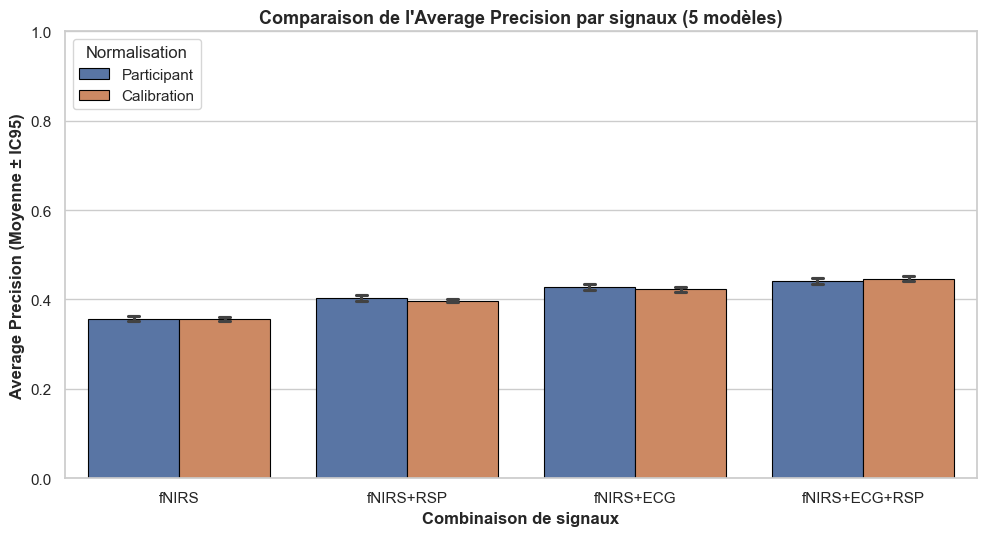

In [7]:
def plot_ap_per_modality_comparison(df, metric=PRIMARY_METRIC):
    col = f"{metric}_mean"
    fig, ax = plt.subplots(figsize=(10, 5.5))
    
    # Barplot avec estimation de l'IC95% (ou écart-type) via Seaborn
    sns.barplot(
        data=df,
        x="file_label",
        y=col,
        hue="norm_mode",
        palette=NORM_PALETTE,
        errorbar=("ci", 95),
        capsize=0.1,
        edgecolor="black",
        linewidth=0.8,
        ax=ax
    )
    
    ax.set_xlabel("Combinaison de signaux", fontweight="bold")
    ax.set_ylabel(f"{metric.replace('_', ' ').title()} (Moyenne ± IC95)", fontweight="bold")
    ax.set_title(f"Comparaison de l'Average Precision par signaux (5 modèles)", fontweight="bold")
    ax.legend(title="Normalisation", loc="upper left")
    ax.set_ylim(0, 1.0)
    
    fig.tight_layout()
    savefig(fig, "01_comp_modalities_AP_bars")

plot_ap_per_modality_comparison(summary)

## Cellule 3 : Graphe 2 — Apport des modalités (Δ AP vs fNIRS seule) (Barres collées)

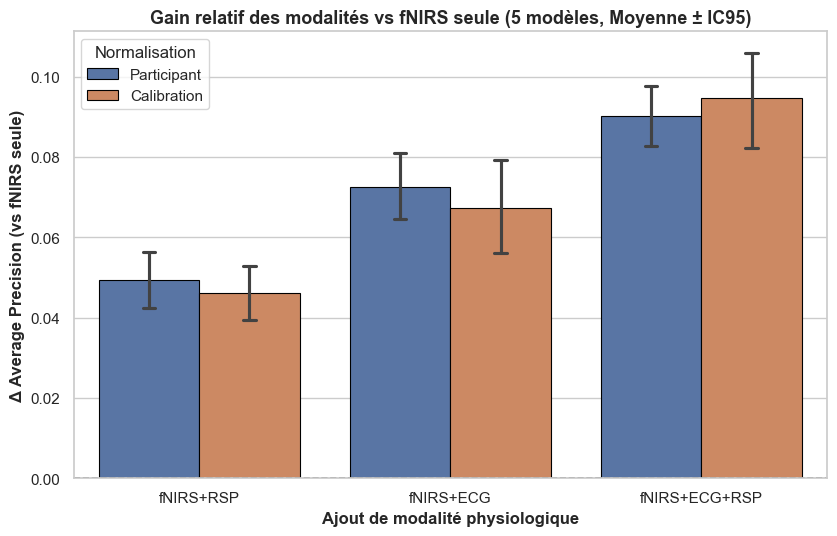

In [12]:
def plot_modality_delta_comparison(df, metric=PRIMARY_METRIC):
    col = f"{metric}_mean"
    keys = ["dataset_folder", "reduction_mode", "model", "norm_mode"]
    
    # 1. Isolation de la baseline mono-modale fNIRS
    base = (
        df[df["dataset_file"] == BASELINE_FILE][keys + [col]]
        .rename(columns={col: "base_val"})
    )
    
    # 2. Calcul du delta (combinaison - baseline)
    merged = df.merge(base, on=keys, how="inner")
    merged["delta"] = merged[col] - merged["base_val"]
    
    # 3. FILTRE STRICT : On supprime la modalité de référence fNIRS de l'axe
    merged = merged[merged["dataset_file"] != BASELINE_FILE].copy()
    
    # Ré-indexation des catégories pour supprimer la modalité 'fNIRS' de l'axe X
    non_baseline_files = [f for f in FILE_ORDER if f != BASELINE_FILE]
    non_baseline_labels = [FILE_LABELS[f] for f in non_baseline_files]
    merged["file_label"] = pd.Categorical(
        merged["file_label"], 
        categories=non_baseline_labels, 
        ordered=True
    )
    
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    sns.barplot(
        data=merged,
        x="file_label",
        y="delta",
        hue="norm_mode",
        palette=NORM_PALETTE,
        errorbar=("ci", 95),
        capsize=0.1,
        edgecolor="black",
        linewidth=0.8,
        ax=ax
    )
    
    # Ligne de référence à 0 (performance équivalente à fNIRS seule)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.2, alpha=0.8)
    
    ax.set_xlabel("Ajout de modalité physiologique", fontweight="bold")
    ax.set_ylabel(f"Δ {metric.replace('_', ' ').title()} (vs fNIRS seule)", fontweight="bold")
    ax.set_title(f"Gain relatif des modalités vs fNIRS seule (5 modèles, Moyenne ± IC95)", fontweight="bold")
    ax.legend(title="Normalisation", loc="upper left")
    
    fig.tight_layout()
    savefig(fig, "02_comp_modality_delta_bars_no_baseline")

plot_modality_delta_comparison(summary)

## Cellule 4 : Graphe 3 — Average Precision par taille de fenêtre (Barres collées)

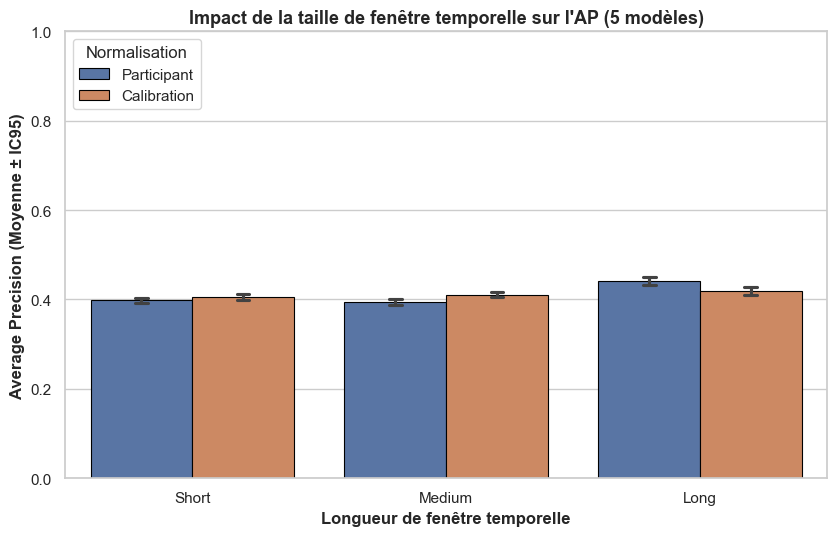

In [9]:
def plot_window_size_comparison(df, metric=PRIMARY_METRIC):
    col = f"{metric}_mean"
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    
    sns.barplot(
        data=df,
        x="folder_label",
        y=col,
        hue="norm_mode",
        palette=NORM_PALETTE,
        errorbar=("ci", 95),
        capsize=0.1,
        edgecolor="black",
        linewidth=0.8,
        ax=ax
    )
    
    ax.set_xlabel("Longueur de fenêtre temporelle", fontweight="bold")
    ax.set_ylabel(f"{metric.replace('_', ' ').title()} (Moyenne ± IC95)", fontweight="bold")
    ax.set_title(f"Impact de la taille de fenêtre temporelle sur l'AP (5 modèles)", fontweight="bold")
    ax.legend(title="Normalisation", loc="upper left")
    ax.set_ylim(0, 1.0)
    
    fig.tight_layout()
    savefig(fig, "03_comp_window_size_AP_bars")

plot_window_size_comparison(summary)

## Cellule 5 : Graphe 4 — Boxplot AP par taille de fenêtre et par modèle (2 volets côte à côte)

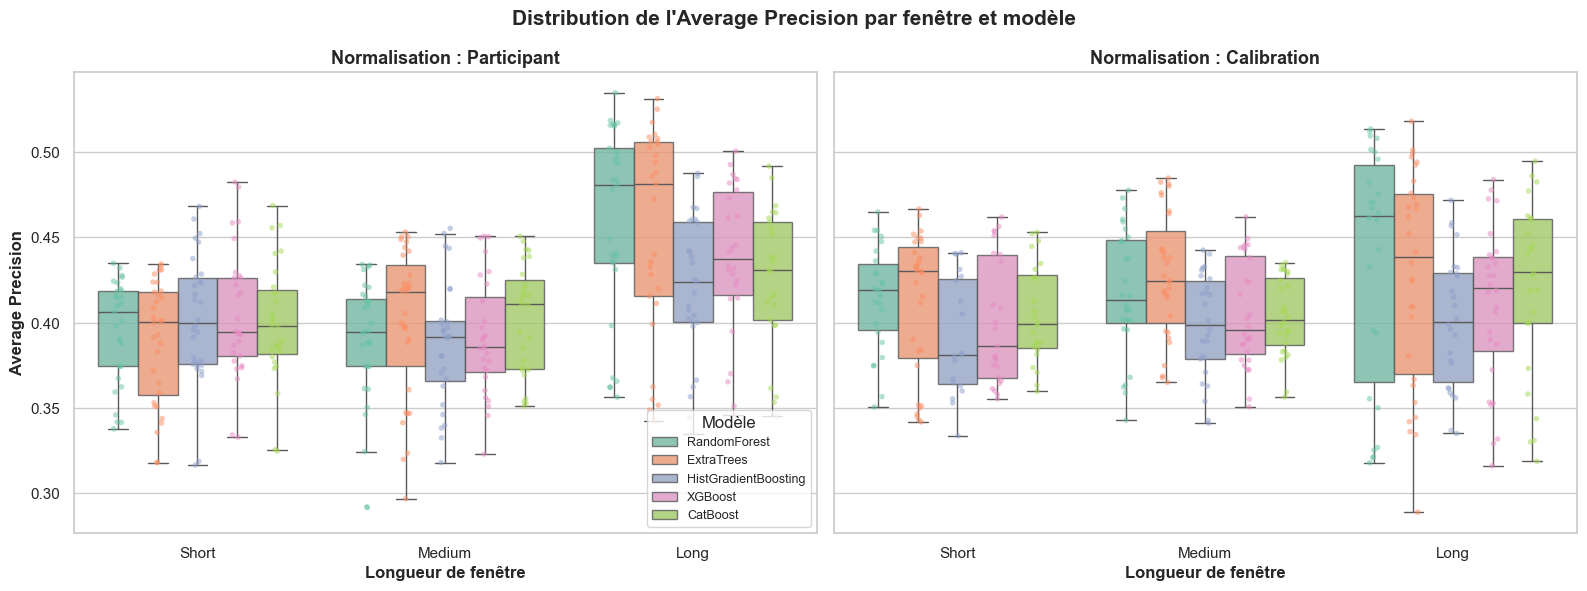

In [10]:
def plot_window_per_model_boxplots(df, metric=PRIMARY_METRIC):
    col = f"{metric}_mean"
    
    # 2 sous-graphiques côte à côte, axe Y partagé
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    
    norms = ["Participant", "Calibration"]
    for i, norm in enumerate(norms):
        ax = axes[i]
        sub_df = df[df["norm_mode"] == norm]
        
        sns.boxplot(
            data=sub_df,
            x="folder_label",
            y=col,
            hue="model",
            hue_order=KEEP_MODELS,
            palette="Set2",
            ax=ax,
            showfliers=False,
            boxprops=dict(alpha=0.8)
        )
        
        # Ajout des points individuels pour voir la dispersion réelle
        sns.stripplot(
            data=sub_df,
            x="folder_label",
            y=col,
            hue="model",
            hue_order=KEEP_MODELS,
            palette="Set2",
            dodge=True,
            alpha=0.5,
            size=4,
            ax=ax,
            legend=False
        )
        
        ax.set_title(f"Normalisation : {norm}", fontweight="bold")
        ax.set_xlabel("Longueur de fenêtre", fontweight="bold")
        if i == 0:
            ax.set_ylabel(f"{metric.replace('_', ' ').title()}", fontweight="bold")
            ax.legend(title="Modèle", loc="lower right", fontsize=9)
        else:
            ax.set_ylabel("")
            ax.legend().remove()
            
    fig.suptitle(f"Distribution de l'Average Precision par fenêtre et modèle", fontsize=15, fontweight="bold")
    fig.tight_layout()
    savefig(fig, "04_boxplot_window_by_model")

plot_window_per_model_boxplots(summary)

## Cellule 6 : Graphe 5 — Boxplot AP par combinaison de signaux et par modèle (2 volets côte à côte)

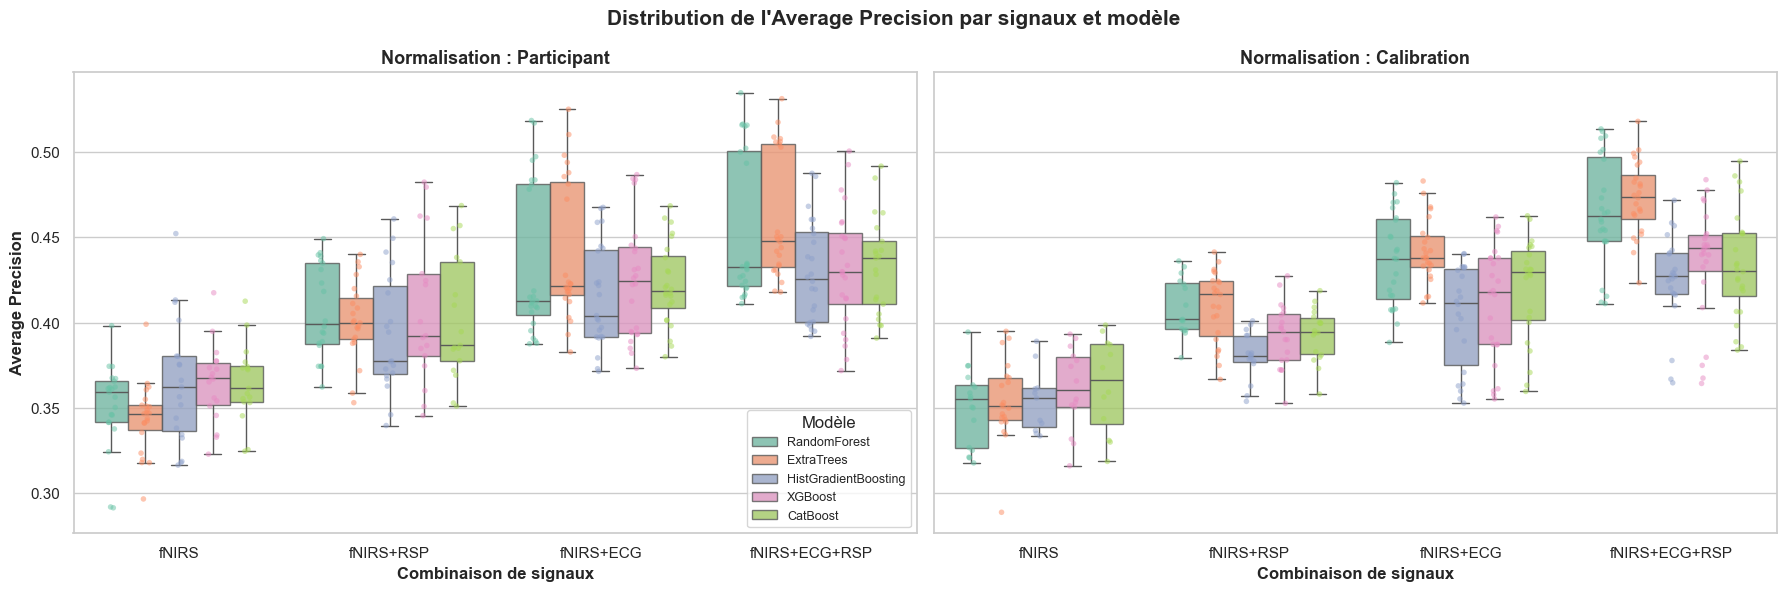

In [11]:
def plot_modality_per_model_boxplots(df, metric=PRIMARY_METRIC):
    col = f"{metric}_mean"
    
    # 2 sous-graphiques côte à côte, axe Y partagé
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
    
    norms = ["Participant", "Calibration"]
    for i, norm in enumerate(norms):
        ax = axes[i]
        sub_df = df[df["norm_mode"] == norm]
        
        sns.boxplot(
            data=sub_df,
            x="file_label",
            y=col,
            hue="model",
            hue_order=KEEP_MODELS,
            palette="Set2",
            ax=ax,
            showfliers=False,
            boxprops=dict(alpha=0.8)
        )
        
        sns.stripplot(
            data=sub_df,
            x="file_label",
            y=col,
            hue="model",
            hue_order=KEEP_MODELS,
            palette="Set2",
            dodge=True,
            alpha=0.5,
            size=4,
            ax=ax,
            legend=False
        )
        
        ax.set_title(f"Normalisation : {norm}", fontweight="bold")
        ax.set_xlabel("Combinaison de signaux", fontweight="bold")
        if i == 0:
            ax.set_ylabel(f"{metric.replace('_', ' ').title()}", fontweight="bold")
            ax.legend(title="Modèle", loc="lower right", fontsize=9)
        else:
            ax.set_ylabel("")
            ax.legend().remove()
            
    fig.suptitle(f"Distribution de l'Average Precision par signaux et modèle", fontsize=15, fontweight="bold")
    fig.tight_layout()
    savefig(fig, "05_boxplot_signals_by_model")

plot_modality_per_model_boxplots(summary)

C:\Users\Ulysse\AppData\Local\Temp\ipykernel_15144\644417413.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right", fontsize=9.5)


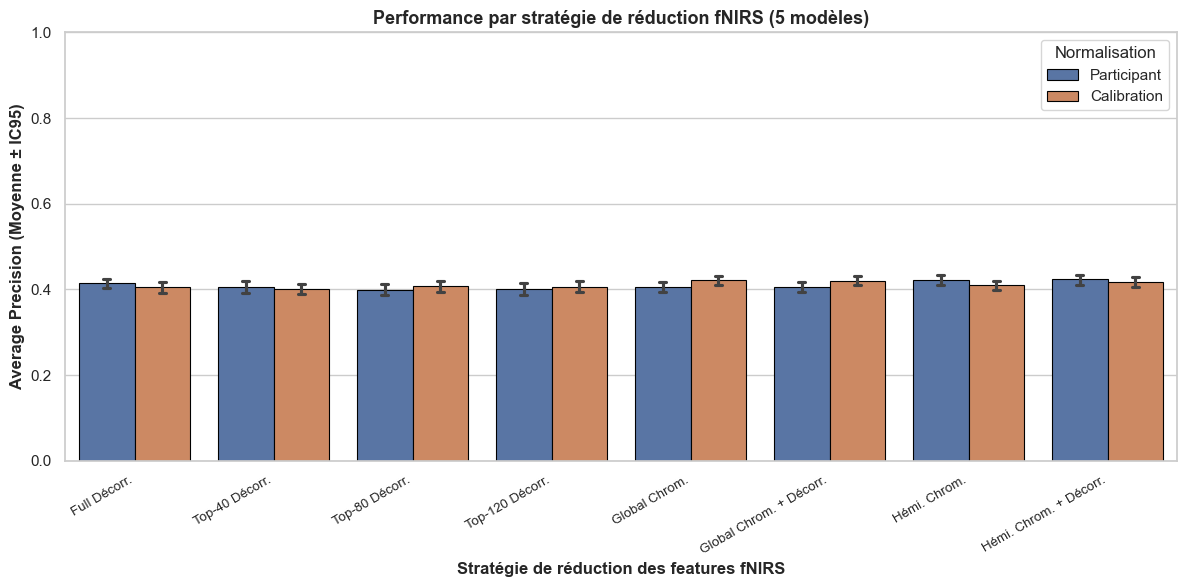

In [14]:
def plot_reduction_ap_bars_comparison(df, metric=PRIMARY_METRIC):
    col = f"{metric}_mean"
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    sns.barplot(
        data=df,
        x="reduction_label",
        y=col,
        hue="norm_mode",
        palette=NORM_PALETTE,
        errorbar=("ci", 95),
        capsize=0.1,
        edgecolor="black",
        linewidth=0.8,
        ax=ax
    )
    
    ax.set_xlabel("Stratégie de réduction des features fNIRS", fontweight="bold")
    ax.set_ylabel(f"{metric.replace('_', ' ').title()} (Moyenne ± IC95)", fontweight="bold")
    ax.set_title("Performance par stratégie de réduction fNIRS (5 modèles)", fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right", fontsize=9.5)
    ax.set_ylim(0, 1.0)
    ax.legend(title="Normalisation", loc="upper right")
    
    fig.tight_layout()
    savefig(fig, "06_comp_reduction_AP_bars")

plot_reduction_ap_bars_comparison(summary)

C:\Users\Ulysse\AppData\Local\Temp\ipykernel_15144\1317111969.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
C:\Users\Ulysse\AppData\Local\Temp\ipykernel_15144\1317111969.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)


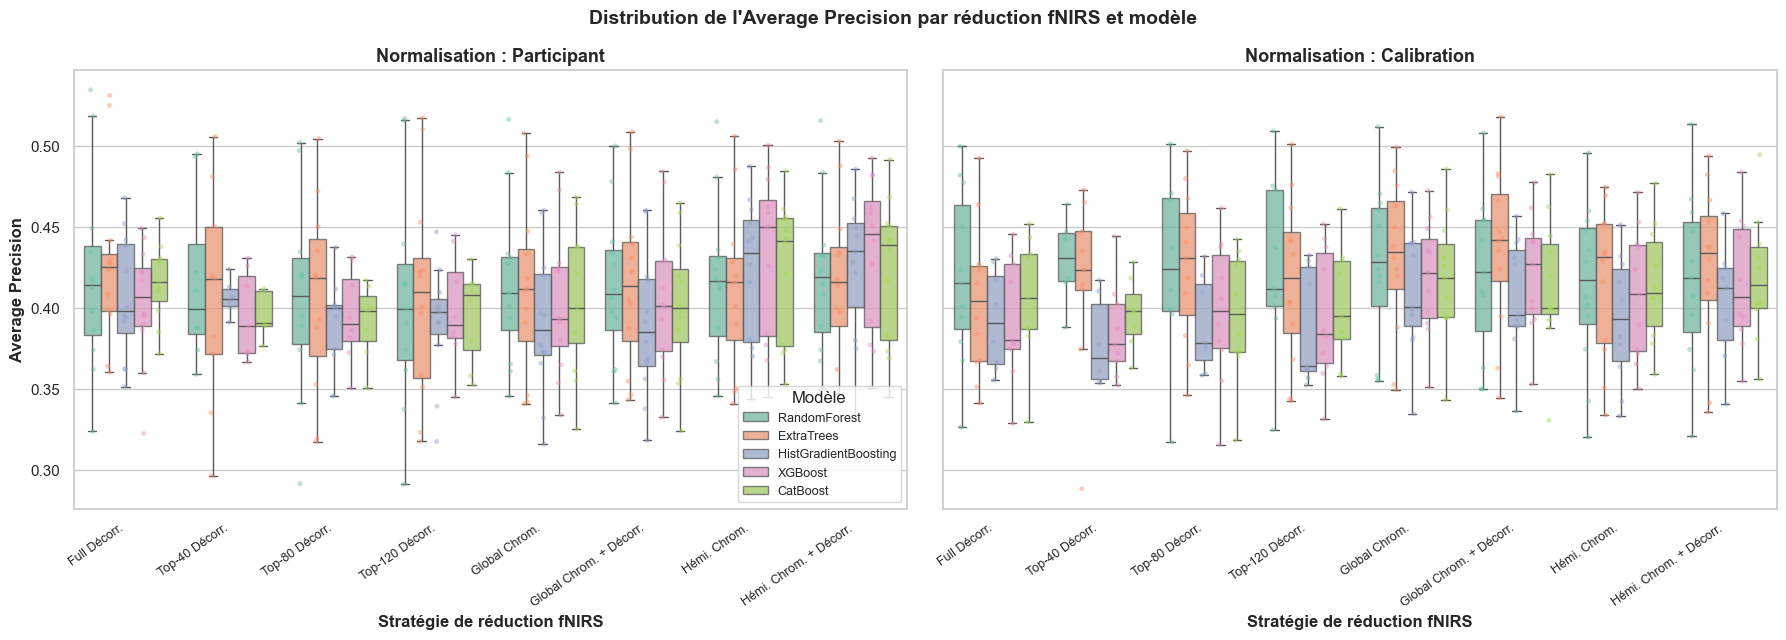

In [15]:
def plot_reduction_per_model_boxplots(df, metric=PRIMARY_METRIC):
    col = f"{metric}_mean"
    
    # 2 sous-graphiques côte à côte avec axe Y partagé
    fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), sharey=True)
    
    norms = ["Participant", "Calibration"]
    for i, norm in enumerate(norms):
        ax = axes[i]
        sub_df = df[df["norm_mode"] == norm]
        
        # Boîtes à moustaches
        sns.boxplot(
            data=sub_df,
            x="reduction_label",
            y=col,
            hue="model",
            hue_order=KEEP_MODELS,
            palette="Set2",
            ax=ax,
            showfliers=False,
            boxprops=dict(alpha=0.75)
        )
        
        # Points réels (stripplot)
        sns.stripplot(
            data=sub_df,
            x="reduction_label",
            y=col,
            hue="model",
            hue_order=KEEP_MODELS,
            palette="Set2",
            dodge=True,
            alpha=0.45,
            size=3.5,
            ax=ax,
            legend=False
        )
        
        ax.set_title(f"Normalisation : {norm}", fontweight="bold")
        ax.set_xlabel("Stratégie de réduction fNIRS", fontweight="bold")
        ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
        
        if i == 0:
            ax.set_ylabel(f"{metric.replace('_', ' ').title()}", fontweight="bold")
            ax.legend(title="Modèle", loc="lower right", fontsize=9)
        else:
            ax.set_ylabel("")
            ax.legend().remove()
            
    fig.suptitle("Distribution de l'Average Precision par réduction fNIRS et modèle", fontsize=14, fontweight="bold")
    fig.tight_layout()
    savefig(fig, "07_boxplot_reduction_by_model")

plot_reduction_per_model_boxplots(summary)

In [ ]:
# ============================================================
# EXTRACTION DU TOP FEATURES 
# 1. Modèles performants uniquement (AP >= Médiane & ROC_low > 0.50)
# 2. Stables sur 5/5 folds
# 3. Tri : n_best_configs (desc) -> mean_global_rank (asc) -> mean_global_importance (desc)
# ============================================================

TOP_N_DISPLAY = 15
MIN_AP_PERCENTILE = 0.50  # Top 50% des meilleures configurations

# 1. Identifier les configurations performantes parmi nos 5 modèles
valid_configs = summary[
    (summary["roc_auc_ci95_low"] > GUARD_ROC_CI_LOW) & 
    (summary["average_precision_mean"] >= summary["average_precision_mean"].quantile(MIN_AP_PERCENTILE))
][["dataset_folder", "dataset_file", "reduction_mode", "model", "norm_mode", "average_precision_mean"]]

print(f"Configurations performantes retenues : {len(valid_configs)} / {len(summary)}")


def load_stability_sheets(excel_path, norm_label):
    if not excel_path.exists():
        print(f"[ERREUR] Fichier introuvable : {excel_path}")
        return pd.DataFrame()
    
    df = pd.read_excel(excel_path, sheet_name="model_features_stability")
    df["norm_mode"] = norm_label
    return df
# 2. Charger les feuilles de stabilité
stab_part = load_stability_sheets(EXCEL_PARTICIPANT, "Participant")
stab_calib = load_stability_sheets(EXCEL_CALIBRATION, "Calibration")
stab_all = pd.concat([stab_part, stab_calib], ignore_index=True)

# 3. Filtre strict : 5 modèles uniquement
stab_all = stab_all[stab_all["model"].isin(KEEP_MODELS)].copy()

# 4. Jointure : Ne garder que les features des configurations performantes
stab_valid = stab_all.merge(
    valid_configs,
    on=["dataset_folder", "dataset_file", "reduction_mode", "model", "norm_mode"],
    how="inner"
)

# 5. Filtre : Stable sur les 5 folds de chaque configuration
stab_valid_5folds = stab_valid[stab_valid["n_folds_in_top"] == 5].copy()

# 6. Agrégation par Feature et par Normalisation
feature_ranking_option1 = (
    stab_valid_5folds
    .groupby(["norm_mode", "feature", "modality"], as_index=False)
    .agg(
        n_best_configs=("model", "count"),                               # 1er critère : Récurrence
        mean_global_rank=("mean_rank", "mean"),                          # 2e critère  : Rang moyen (1 = meilleur)
        mean_global_importance=("mean_ranking_importance_norm", "mean")   # 3e critère  : Importance moyenne (%)
    )
)

# 7. Tri selon :
#    1 - n_best_configs (descendant)
#    2 - mean_global_rank (ascendant)
#    3 - mean_global_importance (descendant)
feature_ranking_option1 = (
    feature_ranking_option1
    .sort_values(
        by=["norm_mode", "n_best_configs", "mean_global_rank", "mean_global_importance"],
        ascending=[True, False, True, False]
    )
    .reset_index(drop=True)
)

# Extraction des Top 15
top_part_opt1 = feature_ranking_option1[feature_ranking_option1["norm_mode"] == "Participant"].head(TOP_N_DISPLAY)
top_calib_opt1 = feature_ranking_option1[feature_ranking_option1["norm_mode"] == "Calibration"].head(TOP_N_DISPLAY)

print(f"\n--- TOP 5 PARTICIPANT ---")
display(top_part_opt1.head(5))

print(f"\n--- TOP 5 CALIBRATION ---")
display(top_calib_opt1.head(5))

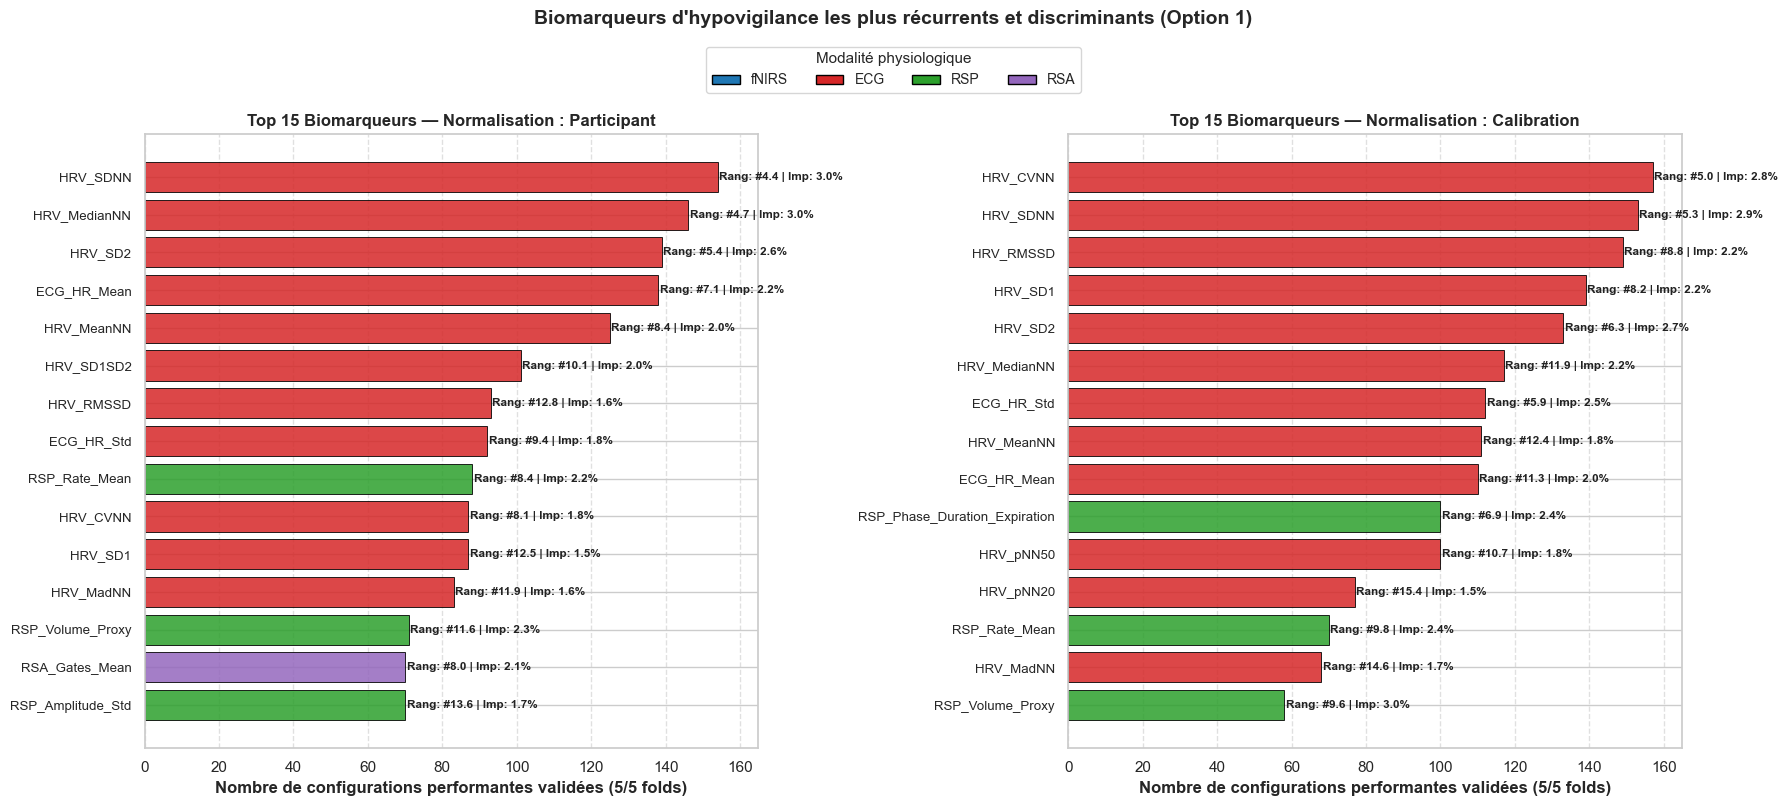

In [23]:
# ============================================================
# FIGURE : TOP 15 BIOMARQUEURS ROBUSTES 
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), sharex=True)

panels = [
    ("Participant", top_part_opt1, axes[0]),
    ("Calibration", top_calib_opt1, axes[1])
]

for norm_name, data, ax in panels:
    data_plot = data.iloc[::-1].copy()  # Meilleure feature en haut
    
    # Couleurs par modalité
    bar_colors = [MODALITY_COLORS.get(m, "#7f7f7f") for m in data_plot["modality"]]
    y_pos = np.arange(len(data_plot))
    
    # Longueur de barre = Nombre de configurations performantes validées
    bars = ax.barh(
        y_pos, 
        data_plot["n_best_configs"], 
        color=bar_colors, 
        edgecolor="black", 
        linewidth=0.7, 
        alpha=0.85
    )
    
    # Annotations sur les barres : Rang moyen et Importance relative (%)
    for i, (bar, r) in enumerate(zip(bars, data_plot.itertuples(index=False))):
        ax.text(
            bar.get_width() + 0.4,
            bar.get_y() + bar.get_height()/2,
            f"Rang: #{r.mean_global_rank:.1f} | Imp: {r.mean_global_importance*100:.1f}%",
            va="center",
            fontsize=8.5,
            fontweight="semibold",
            color="#222222"
        )
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(data_plot["feature"], fontsize=9.5)
    ax.set_xlabel("Nombre de configurations performantes validées (5/5 folds)", fontweight="bold")
    ax.set_title(f"Top {TOP_N_DISPLAY} Biomarqueurs — Normalisation : {norm_name}", fontweight="bold", fontsize=12)
    ax.grid(axis="x", linestyle="--", alpha=0.6)

# Légende des modalités
from matplotlib.patches import Patch
mod_legends = [
    Patch(facecolor=MODALITY_COLORS[m], edgecolor="black", label=m)
    for m in ["fNIRS", "ECG", "RSP", "RSA"] if m in MODALITY_COLORS
]
fig.legend(
    handles=mod_legends,
    title="Modalité physiologique",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    fontsize=10,
    title_fontsize=11
)

fig.suptitle("Biomarqueurs d'hypovigilance les plus récurrents et discriminants (Option 1)", fontsize=14, fontweight="bold", y=1.07)
fig.tight_layout()
savefig(fig, "08_top_features_option1_recurrence_rank")